In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

%matplotlib inline

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

In [2]:
PROJECT_DIR = Path.cwd().parent

DATA_PATH = PROJECT_DIR / "dataset" / "meajor_cleaned_preprocessed.csv"
OUTPUT_DIR = PROJECT_DIR / "outputs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset path:", DATA_PATH)
print("Output directory:", OUTPUT_DIR)

Dataset path: d:\spamEmail\unsaturated\dataset\meajor_cleaned_preprocessed.csv
Output directory: d:\spamEmail\unsaturated\outputs


In [3]:
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (108685, 20)


,sender,sender_domain,receiver,receiver_domain,date,subject,content_types,body,urls,url_count,url_length_max,url_length_avg,url_subdom_max,url_subdom_avg,attachment_count,has_attachments,attachment_types,language,source,label
0,d66e9e64b006d6bca649f1c945129c42c43836872b2ead...,enron.com,35c5a9fb9fba3b8737ed7cef2a87e427a73db4fca85f6b...,enron.com,2001-06-29 09:37:04-05:00,[ORGANIZATION] failover plan.,text/plain,"Hi [NAME], \n\nTonight we are rolling out a n...",NaN,0.0,0.0,0.0,0.0,0.0,0.0,False,NaN,en,trec5,0.0
1,0907d5c64598aa2639154ed4e1556be615669e40052a1f...,enron.com,aa2c35499eae5999bf6080453cc719a891da2bb0c3803d...,enron.com,2001-06-29 08:39:30-05:00,RE: Intranet Site,text/plain,"[NAME] r these new?\tIntranet Site\n\n[NAME],\...",http://eastpower.dev.corp.enron.com/summary/pj...,3.0,60.0,58.0,3.0,3.0,0.0,False,NaN,en,trec5,0.0
2,7c3201a5ff8c5985218f1e3f11e330dc0242bbd28c6c20...,enron.com,a736837579feb601fbf6c0657d3d93689774afa6491bb9...,enron.com;enron.com,2001-06-29 10:35:17-05:00,FW: [ORGANIZATION] Company information,text/plain,"[NAME]/[NAME],\n\nWe are currently trading und...",NaN,0.0,0.0,0.0,0.0,0.0,0.0,False,NaN,en,trec5,0.0
3,8531d54a169c4af106b9ea2165d4986b8cc10fc0a6bb9b...,enron.com,765a3ec4a67e40118d22de5729b05d090a1b59cb443bf6...,enron.com;enron.com,2001-06-29 10:40:02-05:00,New Master Physical,text/plain,[NAME] and [NAME] -\n\nAttached is a worksheet...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,False,NaN,en,trec5,0.0
4,7c3201a5ff8c5985218f1e3f11e330dc0242bbd28c6c20...,enron.com,ce418c97ac415706338972e1dbbd99ebb8c617b5c937a3...,enron.com;enron.com;enron.com,2001-06-29 10:48:00-05:00,FW: [ORGANIZATION]/Mirant GISB,text/plain,FYI. Below is a copy of my communication with ...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,False,NaN,en,trec5,0.0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 108685 entries, 0 to 108684
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   sender            108191 non-null  str    
 1   sender_domain     108191 non-null  str    
 2   receiver          106314 non-null  str    
 3   receiver_domain   106314 non-null  str    
 4   date              108685 non-null  str    
 5   subject           107230 non-null  str    
 6   content_types     108684 non-null  str    
 7   body              108684 non-null  str    
 8   urls              64052 non-null   str    
 9   url_count         108685 non-null  float64
 10  url_length_max    108685 non-null  float64
 11  url_length_avg    108685 non-null  float64
 12  url_subdom_max    108685 non-null  float64
 13  url_subdom_avg    108685 non-null  float64
 14  attachment_count  108685 non-null  float64
 15  has_attachments   108685 non-null  bool   
 16  attachment_types  1666 non-null

In [5]:
print("Total columns:", len(df.columns))

for column in df.columns:
    print(column)

Total columns: 20
sender
sender_domain
receiver
receiver_domain
date
subject
content_types
body
urls
url_count
url_length_max
url_length_avg
url_subdom_max
url_subdom_avg
attachment_count
has_attachments
attachment_types
language
source
label


In [6]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
sender,108191,55562,2a0c86a8fa25e09e3702b5442b2a35f7b59011badd551e...,2050,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sender_domain,108191,28464,enron.com,21684,NaN,NaN,NaN,NaN,NaN,NaN,NaN
receiver,106314,17580,247e0a5daf10ac2f4a2ec564931b09941a066488d3fa53...,4484,NaN,NaN,NaN,NaN,NaN,NaN,NaN
receiver_domain,106314,6366,enron.com,30845,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,108685,107474,2002-03-01 04:10:35+00:00,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subject,107230,68486,RE:,895,NaN,NaN,NaN,NaN,NaN,NaN,NaN
content_types,108684,16,text/plain,70992,NaN,NaN,NaN,NaN,NaN,NaN,NaN
body,108684,103518,Start Date: [DATE]; HourAhead hour: [TIME]; N...,667,NaN,NaN,NaN,NaN,NaN,NaN,NaN
urls,64052,38352,https://stat.ethz.ch/mailman/listinfo/r-help\n...,2552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
url_count,108685.0,NaN,NaN,NaN,3.308138,10.507161,0.0,0.0,1.0,2.0,553.0


In [7]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_values = missing_values.sort_values(
    by="Missing Percentage",
    ascending=False
)

missing_values

,Missing Count,Missing Percentage
attachment_types,107019,98.467130
urls,44633,41.066385
receiver_domain,2371,2.181534
receiver,2371,2.181534
subject,1455,1.338731
sender_domain,494,0.454525
sender,494,0.454525
body,1,0.000920
source,1,0.000920
language,1,0.000920


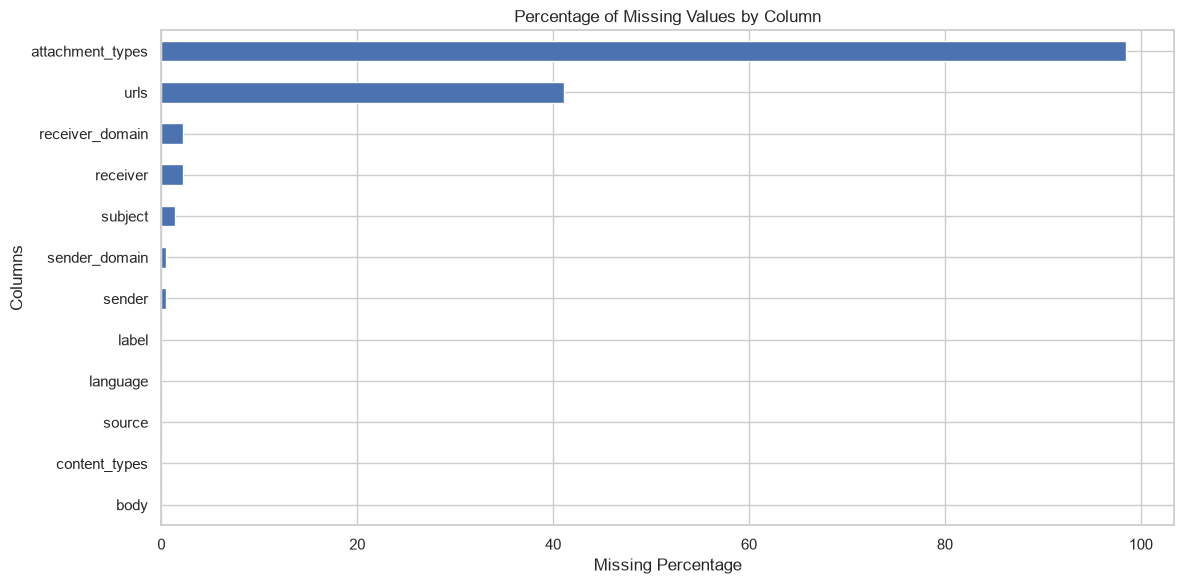

In [8]:
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_percent = missing_percent[missing_percent > 0]

plt.figure(figsize=(12, 6))

missing_percent.sort_values().plot(kind="barh")

plt.title("Percentage of Missing Values by Column")
plt.xlabel("Missing Percentage")
plt.ylabel("Columns")
plt.tight_layout()
plt.show()

In [9]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)
print(
    "Duplicate percentage:",
    round((duplicate_count / len(df)) * 100, 4),
    "%"
)

Number of duplicate rows: 13
Duplicate percentage: 0.012 %


In [10]:
print("Label distribution:")
print(df["label"].value_counts(dropna=False))

print("\nLabel percentage:")
print(
    (df["label"].value_counts(normalize=True, dropna=False) * 100).round(2)
)

Label distribution:
label
0.0    60650
1.0    48034
NaN        1
Name: count, dtype: int64

Label percentage:
label
0.0    55.8
1.0    44.2
NaN     0.0
Name: proportion, dtype: float64


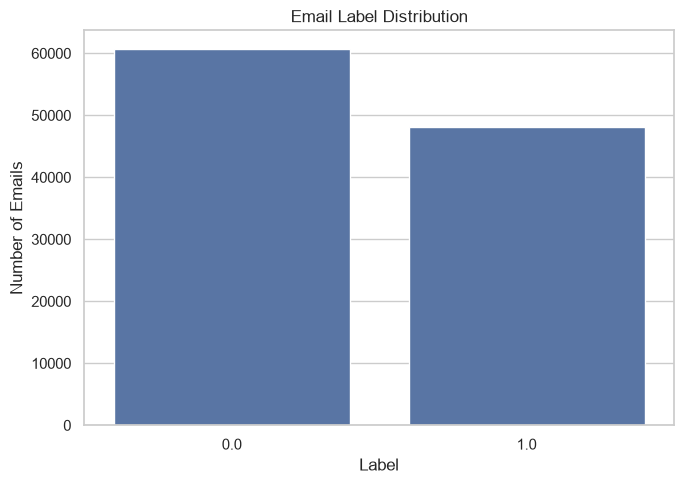

In [11]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="label")

plt.title("Email Label Distribution")
plt.xlabel("Label")
plt.ylabel("Number of Emails")
plt.tight_layout()
plt.show()

In [12]:
print("Emails from each source:")
print(df["source"].value_counts(dropna=False))

Emails from each source:
source
trec5    49583
trec7    44096
trec6    15005
NaN          1
Name: count, dtype: int64


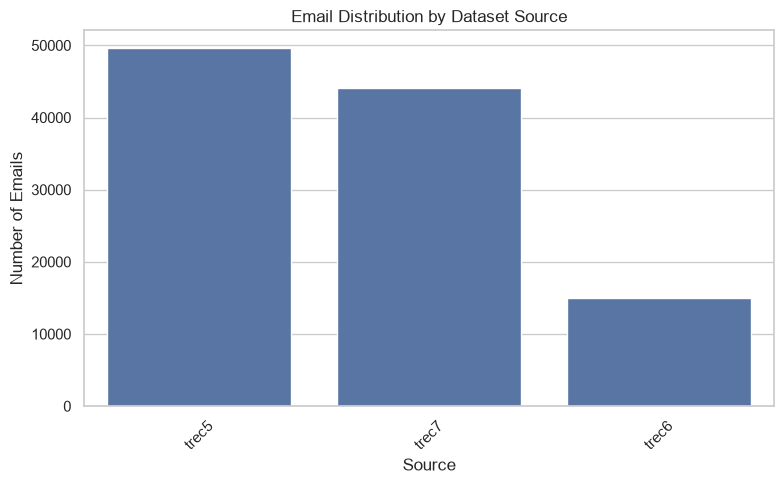

In [13]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="source",
    order=df["source"].value_counts().index
)

plt.title("Email Distribution by Dataset Source")
plt.xlabel("Source")
plt.ylabel("Number of Emails")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
source_label_table = pd.crosstab(
    df["source"],
    df["label"],
    margins=True
)

source_label_table

label,0.0,1.0,All
source,,,
trec5,29929,19654,49583
trec6,11208,3797,15005
trec7,19513,24583,44096
All,60650,48034,108684


In [15]:
df_clean = df.copy()

text_columns = [
    "sender",
    "sender_domain",
    "receiver",
    "receiver_domain",
    "subject",
    "content_types",
    "body",
    "urls",
    "attachment_types",
    "language",
    "source"
]

for column in text_columns:
    df_clean[column] = df_clean[column].fillna("")

print("Missing values after filling text fields:")
print(df_clean.isnull().sum())

Missing values after filling text fields:
sender              0
sender_domain       0
receiver            0
receiver_domain     0
date                0
subject             0
content_types       0
body                0
urls                0
url_count           0
url_length_max      0
url_length_avg      0
url_subdom_max      0
url_subdom_avg      0
attachment_count    0
has_attachments     0
attachment_types    0
language            0
source              0
label               1
dtype: int64


In [16]:
before = len(df_clean)

df_clean = df_clean.dropna(subset=["label"]).copy()

after = len(df_clean)

print("Rows before:", before)
print("Rows after:", after)
print("Rows removed:", before - after)

Rows before: 108685
Rows after: 108684
Rows removed: 1


In [17]:
before = len(df_clean)

df_clean = df_clean.drop_duplicates().copy()

after = len(df_clean)

print("Rows before:", before)
print("Rows after:", after)
print("Duplicate rows removed:", before - after)

Rows before: 108684
Rows after: 108671
Duplicate rows removed: 13


In [18]:
print("Final dataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate rows:")
print(df_clean.duplicated().sum())

print("\nLabel distribution:")
print(df_clean["label"].value_counts())

Final dataset shape: (108671, 20)

Missing values:
0

Duplicate rows:
0

Label distribution:
label
0.0    60637
1.0    48034
Name: count, dtype: int64


In [19]:
CLEANED_DATA_PATH = OUTPUT_DIR / "meajor_cleaned.csv"

df_clean.to_csv(CLEANED_DATA_PATH, index=False)

print("Cleaned dataset saved at:")
print(CLEANED_DATA_PATH)

Cleaned dataset saved at:
d:\spamEmail\unsaturated\outputs\meajor_cleaned.csv


In [20]:
print("DATA UNDERSTANDING AND CLEANING SUMMARY")
print("---------------------------------------")

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("Total emails:", len(df_clean))
print("Total features:", len(df_clean.columns))

print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

print("\nLabel distribution:")
print(df_clean["label"].value_counts())

print("\nSource distribution:")
print(df_clean["source"].value_counts())

DATA UNDERSTANDING AND CLEANING SUMMARY
---------------------------------------
Original dataset shape: (108685, 20)
Cleaned dataset shape: (108671, 20)
Total emails: 108671
Total features: 20
Missing values: 0
Duplicate rows: 0

Label distribution:
label
0.0    60637
1.0    48034
Name: count, dtype: int64

Source distribution:
source
trec5    49572
trec7    44096
trec6    15003
Name: count, dtype: int64
